In [506]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [507]:
train = pd.read_csv("train.csv")
featuresA = ["w0", "hour_sin", "hour_cos", "work_units1"]
featuresB = ["w0", "hour_sin", "hour_cos", "work_units1", "power"]
maskA = train["workshop"] == "A"
maskB = train["workshop"] == "B"

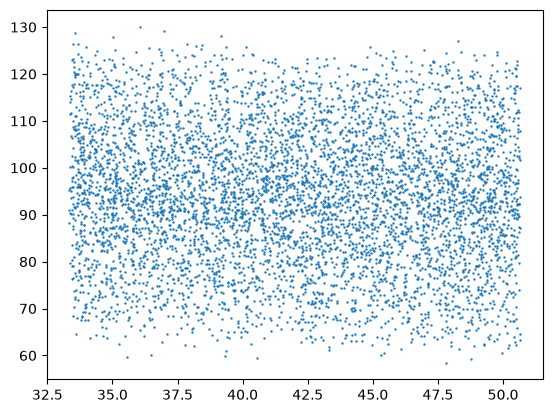

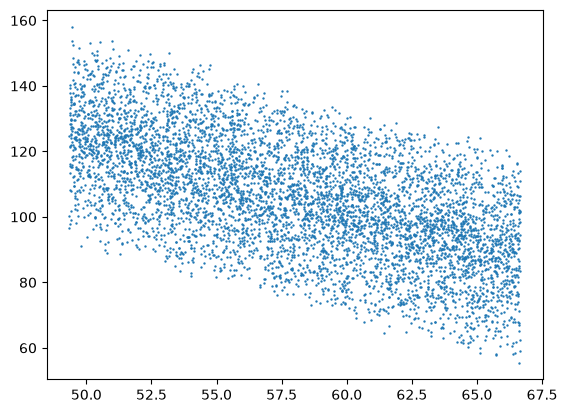

In [508]:
plt.scatter(train[maskA]["power"], train[maskA]["target"], s = 0.5)
plt.show()
plt.scatter(train[maskB]["power"], train[maskB]["target"], s = 0.5)
plt.show()

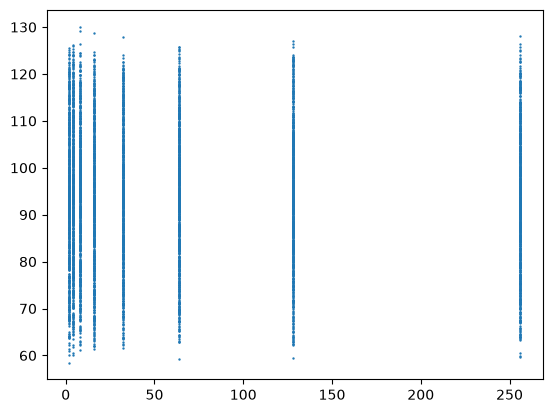

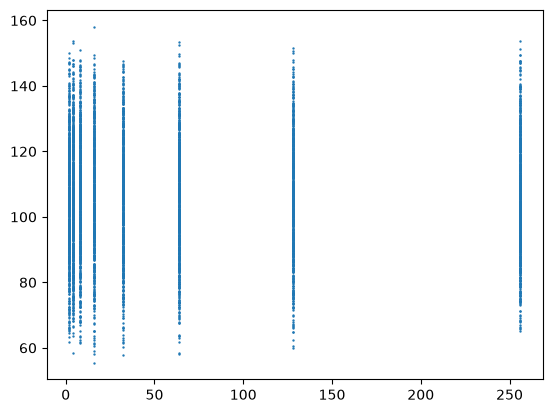

In [509]:
plt.scatter(train[maskA]["robots"], train[maskA]["target"], s = 0.5)
plt.show()
plt.scatter(train[maskB]["robots"], train[maskB]["target"], s = 0.5)
plt.show()

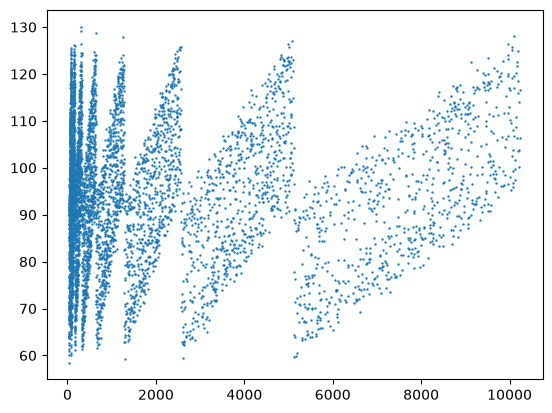

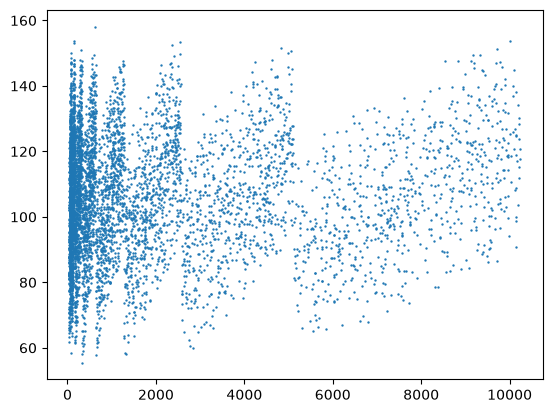

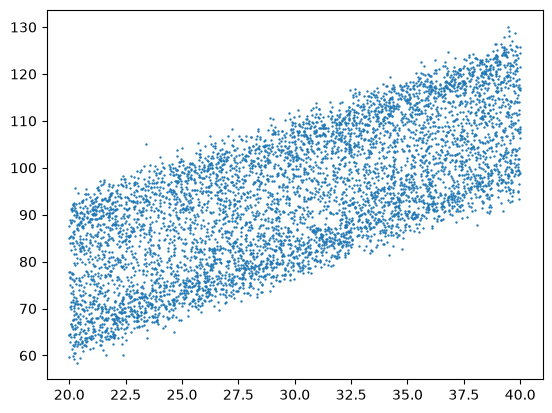

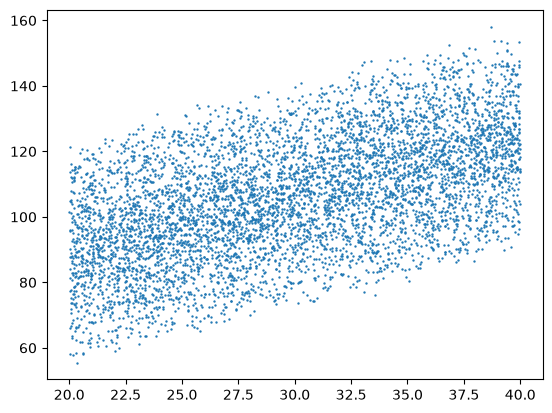

In [510]:
# i = 0.3
# while i < 0.311:
#     print(i)
#     i += 0.0001
#     plt.scatter(np.mod(np.log10(train[maskA]["work_units"]), i), train[maskA]["target"], s = 0.5)
#     plt.show()
plt.scatter(train[maskA]["work_units"], train[maskA]["target"], s = 0.5)
plt.show()
plt.scatter(train[maskB]["work_units"], train[maskB]["target"], s = 0.5)
plt.show()
plt.scatter(train[maskA]["work_units"] / train[maskA]["robots"], train[maskA]["target"], s = 0.5)
plt.show()
plt.scatter(train[maskB]["work_units"] / train[maskB]["robots"], train[maskB]["target"], s = 0.5)
plt.show()

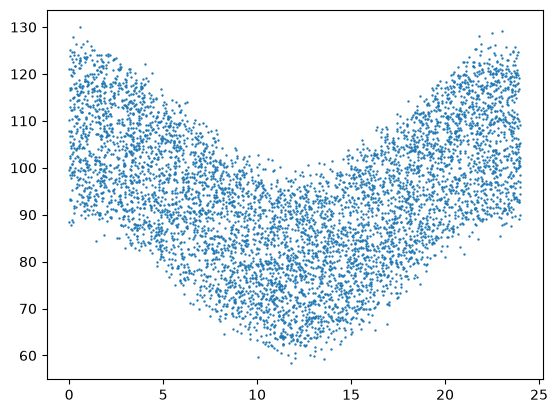

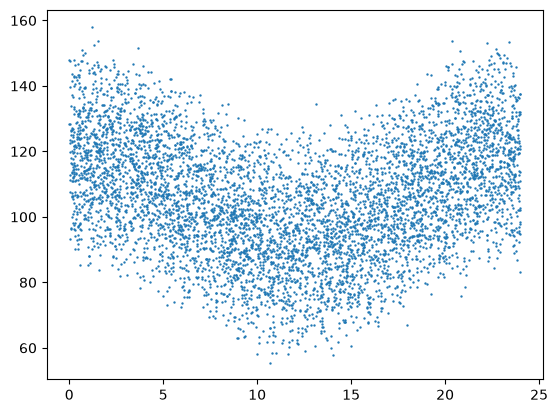

In [511]:
plt.scatter(train[maskA]["hour"], train[maskA]["target"], s = 0.5)
plt.show()
plt.scatter(train[maskB]["hour"], train[maskB]["target"], s = 0.5)
plt.show()

In [512]:
def gradient_step(w, y_true, X, lr):
    n = X.shape[0]
    e = X @ w - y_true
    grad = (2 / n) * ((X.T) @ e)
    return w - lr * grad

def mse(y_pred, y_true):
    return np.sum((y_pred - y_true) ** 2) / y_pred.shape[0]

In [513]:
def format(table):
    table.insert(0, column="w0", value=np.ones(len(table)))
    table["hour_cos"] = np.cos(2 * np.pi * table["hour"] / 24)
    table["hour_sin"] = np.sin(2 * np.pi * table["hour"] / 24)
    table["work_units1"] = table["work_units"] / table["robots"]
    XA = np.array(table[maskA][featuresA])
    y_trueA = np.array(table[maskA]["target"])
    X_stdA = XA.std(axis = 0)
    X_meanA = XA.mean(axis = 0)
    X_meanA[0] = 0
    X_stdA[0] = 1
    X_normA = (XA - X_meanA) / X_stdA
    y_true_normA = (y_trueA - (y_trueA.mean())) / (y_trueA.std())
    XB = np.array(table[maskB][featuresB])
    y_trueB = np.array(table[maskB]["target"])
    X_stdB = XB.std(axis = 0)
    X_meanB = XB.mean(axis = 0)
    X_meanB[0] = 0
    X_stdB[0] = 1
    X_normB = (XB - X_meanB) / X_stdB
    y_true_normB = (y_trueB - (y_trueB.mean())) / (y_trueB.std())
    return XA, y_trueA, X_normA, y_true_normA, y_trueA.mean(), y_trueA.std(), X_meanA, X_stdA, XB, y_trueB, X_normB, y_true_normB, y_trueB.mean(), y_trueB.std(), X_meanB, X_stdB
def format2(table):
    table.insert(0, column="w0", value=np.ones(len(table)))
    table["hour_cos"] = np.cos(2 * np.pi * table["hour"] / 24)
    table["hour_sin"] = np.sin(2 * np.pi * table["hour"] / 24)
    table["work_units1"] = table["work_units"] / table["robots"]
    return table

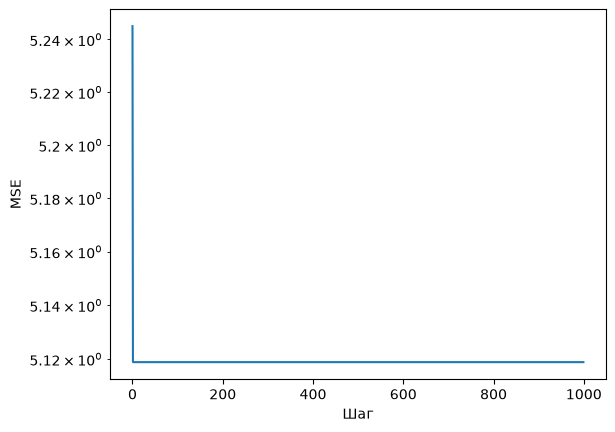

5.245063145412404
5.118841472320808
#########


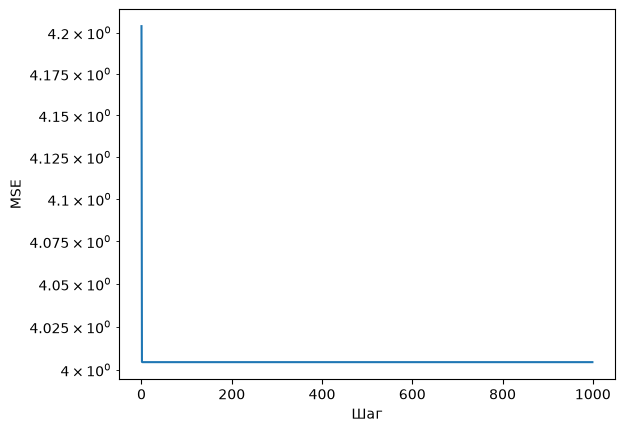

4.203950337960975
4.004414639995345


In [514]:
XA, y_trueA, X_normA, y_true_normA, y_meanA, y_stdA, X_meanA, X_stdA, XB, y_trueB, X_normB, y_true_normB, y_meanB, y_stdB, X_meanB, X_stdB = format(train)
wA = np.zeros(4)
historyA = []
wB = np.zeros(5)
historyB = []
for i in range(1000):
    wA = gradient_step(wA, y_true_normA, X_normA, 0.5)
    predictionA = X_normA @ wA
    historyA.append(mse(predictionA * y_stdA + y_meanA, y_trueA))
    wB = gradient_step(wB, y_true_normB, X_normB, 0.5)
    predictionB = X_normB @ wB
    historyB.append(mse(predictionB * y_stdB + y_meanB, y_trueB))
plt.plot(historyA)
plt.yscale("log")
plt.xlabel("Шаг")
plt.ylabel("MSE")
plt.show()
print(historyA[0])
print(historyA[-1])
print("#########")
plt.plot(historyB)
plt.yscale("log")
plt.xlabel("Шаг")
plt.ylabel("MSE")
plt.show()
print(historyB[0])
print(historyB[-1])

In [515]:
valid = format2(pd.read_csv("validation.csv"))
maskA = valid["workshop"] == "A"
maskB = valid["workshop"] == "B"
X_validA = np.array(valid[maskA][featuresA])
X_valid_normA = (X_validA - X_meanA) / X_stdA
prediction_validA = (X_valid_normA @ wA) * y_stdA + y_meanA
X_validB = np.array(valid[maskB][featuresB])
X_valid_normB = (X_validB - X_meanB) / X_stdB
prediction_validB = (X_valid_normB @ wB) * y_stdB + y_meanB
submission_v = pd.read_csv("baseline_validation.csv")
valid["prediction"] = np.zeros(len(valid))
valid.loc[maskA, "prediction"] = prediction_validA
valid.loc[maskB, "prediction"] = prediction_validB
submission_v["target"] = valid["prediction"]
submission_v.to_csv("submission_valid.csv", index=False)

In [516]:
test = format2(pd.read_csv("test.csv"))
maskA = test["workshop"] == "A"
maskB = test["workshop"] == "B"
X_testA = np.array(test[maskA][featuresA])
X_test_normA = (X_testA - X_meanA) / X_stdA
prediction_testA = (X_test_normA @ wA) * y_stdA + y_meanA
X_testB = np.array(test[maskB][featuresB])
X_test_normB = (X_testB - X_meanB) / X_stdB
prediction_testB = (X_test_normB @ wB) * y_stdB + y_meanB
submission = pd.read_csv("baseline_submission.csv")
test["prediction"] = np.zeros(len(test))
test.loc[maskA, "prediction"] = prediction_testA
test.loc[maskB, "prediction"] = prediction_testB
submission["target"] = test["prediction"]
submission.to_csv("submissionF.csv", index=False)